In [2]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import START,END,StateGraph
from pydantic import BaseModel,Field
from typing import TypedDict,Literal,Annotated
from langchain_core.messages import BaseMessage,HumanMessage
from dotenv import load_dotenv

In [3]:
load_dotenv()  

True

In [ ]:
model=ChatGoogleGenerativeAI(model="gemini-3-flash-preview")

AIMessage(content=[{'type': 'text', 'text': "I'm doing well, thank you for asking! How are you doing today? Is there anything I can help you with?", 'extras': {'signature': 'Eo8DCowDAWkUfROP+5Joz6JfyLWiTPh/E5JAd9BlgGBts77h9g/vlqT7W2w1FttYEDANwqLoYuzRmvOi2ubLYrvKvVYoiDVEltLQQ+FCfdCr2YSkfiQRilDNAbKdzd3eGPZprHO4/lAqwPYXj1WA7QqhMzk+x3FW2vjt2xOHzSGioLuzLeRaKXRuRu9+2KVei7dZ0wUk7gTzIsWUQ2e/Eueqz/gOtXocZXaCP0dzcG7Sd8uyongWmzPnszWxdkdAUoaywGE7+cCBr7OkUE18JcOsbUmLSgCA65asPRmsO17hCc9Kv+Kn/2J9gpNVs53V0rkgZ4r4XIUL64knTuwkk+iygqaSAKkfdpz7JaUZTeOVcetRIRF7csBsMnwVbszlw3fUQyxSbUWS/aktzzHpe/cNgxMqthoDewKphuhRrRs8asNUYuAZJlnqQfTtxGW+d3V9A7MTeu5rcnzEAX8rTsy4uoIzJ+UzYsyGr47LMdP3Lm0eqzInedB7FVlXnNrbyOMsCHZ4M32FDJpDeaMBPwLP'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3-flash-preview', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a14466-c596-72b1-a0fd-64fb21a5cb2c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens'

In [22]:
class ResearchState(TypedDict):
    query: str
    subtopics: list[str]
    search_results: list[str]
    search_notes: list[str]
    report: str
    errors: list[str]

In [36]:
def make_subtopics(state: ResearchState) -> dict:
   try:
     response = model.invoke( f""" You are an AI research assistant. Break the following research query into 4-5 specific subtopics that should be investigated. Return only the subtopics as a numbered list. Query: {state['query']} """ )
     subtopics_text = response.content
    #  print(subtopics_text)
     return {"subtopics": subtopics_text, "search_notes": [
                "Created subtopics for the query."
            ],
            "errors": []}
   except Exception as e:
            return {"errors": [str(e)]}

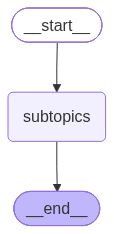

In [37]:
graph=StateGraph(ResearchState)

graph.add_node('subtopics',make_subtopics)
graph.add_edge(START,'subtopics')
graph.add_edge('subtopics',END)

workflow=graph.compile()
workflow

In [41]:
final_state=workflow.invoke({'query': 'Evolution of Electric Vehicles', 'subtopics': [], 'search_results': [], 'search_notes': [], 'report': '', 'errors': []})

In [44]:
result=final_state["subtopics"][0]["text"]
for i, subtopic in enumerate(result.split("\n")):
    print(f" {subtopic.strip()}")

 1. Historical origins and the early 20th-century transition from steam to internal combustion engines.
 2. Breakthroughs in battery chemistry and energy density, from lead-acid to solid-state technology.
 3. The impact of government regulations, subsidies, and global emission standards on market adoption.
 4. Development of charging infrastructure and its integration with smart grid technology.
 5. Lifecycle environmental assessments comparing raw material extraction to traditional vehicle manufacturing.
